# E01 — Digitales y barreras

**Objetivos:** valorar digitales como derivada del precio de una call y replicarlas con call spreads; explicar el
*overhedge*; valorar barreras con fórmulas cerradas y paridad in-out; pasar de observación continua a discreta
(Broadie-Glasserman-Kou); entender las griegas cerca de la barrera; analizar un producto con barrera al 60 % cuando
el subyacente cae al 63 %.

**Fuentes:** Hull cap. 26 (26.9 y 26.10); Schofield, *Equity Derivatives*, cap. 7 y 12.7.2; Broadie, Glasserman y
Kou (1997). Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from scipy.stats import norm
from derivlab.market import sample_market
from derivlab.curves import build_curves
from derivlab.equity import EquityMarket, SSVI
from derivlab.exotics import (bs_spot, digital_flat, digital_smile, call_spread_digital, barrier_price,
                              barrier_price_discrete, bgk_barrier, gbm_paths, barrier_mc, greeks_by_bump)

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()
T1 = 1.0
F1, P1 = mkt.forward(T1), mkt.P(T1)
r1 = -np.log(P1) / T1
q1 = r1 - np.log(F1 / mkt.spot) / T1          # dividends + repo as a yield that reproduces the 1y forward
vol_1y = lambda K: float(surface.vol(np.log(K / F1), T1))
print(f"Index 5,000; 1y forward {F1:,.1f}; r {r1:.3%}; equivalent yield q {q1:.3%}")

Index 5,000; 1y forward 4,910.7; r 1.885%; equivalent yield q 3.688%


## 1. Digitales: la derivada de una call

Una digital *cash-or-nothing* paga 1 si $S_T > K$. Es el límite de un call spread infinitamente estrecho:
$$D(K) = -\frac{\partial C}{\partial K} = e^{-rT}N(d_2) \;-\; \underbrace{\frac{\partial C}{\partial \sigma}\,\frac{\partial \sigma}{\partial K}}_{\text{efecto del smile}}$$
Con skew negativo ($\partial\sigma/\partial K < 0$) la digital call vale más que con volatilidad plana: la
probabilidad neutral al riesgo de acabar por encima del strike es mayor de lo que dice $N(d_2)$.

In [2]:
rows = []
for k_pct in [0.90, 1.00, 1.10]:
    K = k_pct * mkt.spot
    flat = digital_flat(mkt.spot, K, T1, r1, q1, vol_1y(K))
    smile = digital_smile(mkt.spot, K, T1, r1, q1, vol_1y)
    rows.append({"strike": f"{k_pct:.0%}", "vol at strike": vol_1y(K), "digital (flat vol)": flat,
                 "digital (smile)": smile, "smile effect": smile - flat})
dig = pd.DataFrame(rows)
print(dig.to_string(index=False, formatters={"vol at strike": "{:.2%}".format, "digital (flat vol)": "{:.4f}".format,
      "digital (smile)": "{:.4f}".format, "smile effect": "{:+.4f}".format}))
d100 = dig.iloc[1]
print(f"CASE 1y digital call at 100% paying 1: {d100['digital (flat vol)']:.4f} with the strike vol, "
      f"{d100['digital (smile)']:.4f} with the smile")

strike vol at strike digital (flat vol) digital (smile) smile effect
   90%        19.90%             0.6210          0.7283      +0.1072
  100%        16.71%             0.4162          0.5357      +0.1196
  110%        13.86%             0.1840          0.2553      +0.0714
CASE 1y digital call at 100% paying 1: 0.4162 with the strike vol, 0.5357 with the smile


### Replicar con call spreads: el *overhedge*

Quien vende una digital (por ejemplo, el cupón de un autocall) no puede cubrir un salto de 0 a 1 en el strike.
La cubre con un call spread de anchura $w$ y nominal $1/w$. Si lo coloca **por debajo** del strike, el call spread
paga al menos lo mismo que la digital en cualquier escenario: es una cobertura conservadora y su sobrecoste es una
reserva que el banco cobra en el precio (Schofield 12.7.2).

In [3]:
K = mkt.spot
d_true = digital_smile(mkt.spot, K, T1, r1, q1, vol_1y)
over = []
for w_pct in [0.005, 0.01, 0.02, 0.05]:
    w = w_pct * K
    cs = call_spread_digital(mkt.spot, K, T1, r1, q1, vol_1y, w, below=True)
    over.append({"width": f"{w_pct:.1%}", "call spread": cs, "overhedge": cs - d_true,
                 "overhedge on 10% coupon, 100 M": (cs - d_true) * 0.10 * 100e6})
over = pd.DataFrame(over)
print(over.to_string(index=False, formatters={"call spread": "{:.4f}".format, "overhedge": "{:.4f}".format,
      "overhedge on 10% coupon, 100 M": "{:,.0f}".format}))
print(f"CASE a 2% wide call spread overhedges a 10% digital coupon on 100 M EUR by "
      f"{over.iloc[2]['overhedge on 10% coupon, 100 M']:,.0f} EUR")

width call spread overhedge overhedge on 10% coupon, 100 M
 0.5%      0.5418    0.0061                         60,588
 1.0%      0.5478    0.0120                        120,280
 2.0%      0.5594    0.0237                        236,969
 5.0%      0.5923    0.0566                        565,569
CASE a 2% wide call spread overhedges a 10% digital coupon on 100 M EUR by 236,969 EUR


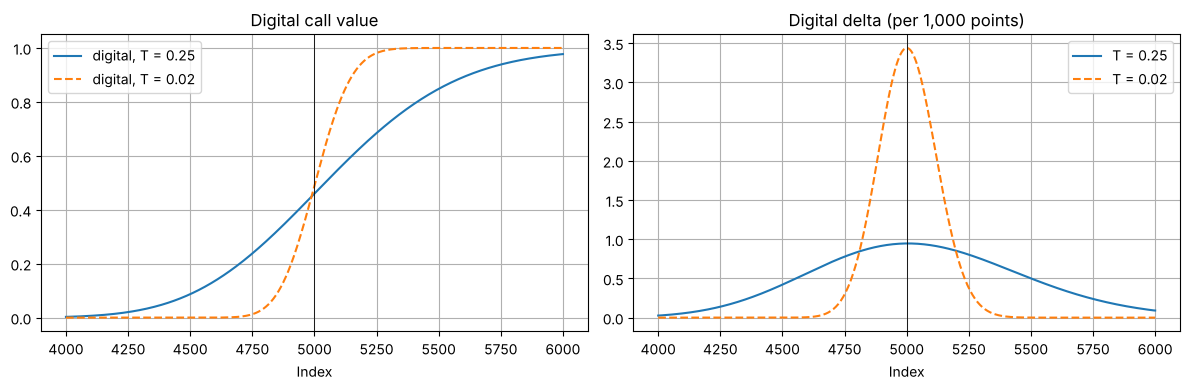

In [4]:
spots = np.linspace(4000, 6000, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for tau, ls in [(0.25, "-"), (1 / 52, "--")]:
    dd = [digital_flat(s, K, tau, r1, q1, vol_1y(K)) for s in spots]
    ax[0].plot(spots, dd, ls, label=f"digital, T = {tau:.2f}")
    delta = np.gradient(dd, spots)
    ax[1].plot(spots, delta * 1000, ls, label=f"T = {tau:.2f}")
ax[0].set_title("Digital call value"); ax[1].set_title("Digital delta (per 1,000 points)")
for a in ax:
    a.axvline(K, color="k", lw=0.6); a.set_xlabel("Index"); a.legend()
plt.tight_layout(); plt.show()

Cerca del vencimiento la delta de la digital se concentra en el strike y se vuelve enorme: cubrirla exactamente
obligaría a comprar y vender grandes cantidades en un rango estrecho. El call spread reparte ese riesgo en una
banda y lo hace manejable.

## 2. Barreras con fórmula cerrada

Una opción *knock-in* nace si el subyacente toca la barrera; una *knock-out* muere. Con observación continua y
volatilidad plana hay fórmulas cerradas (Hull 26.9). Por ejemplo, para una put *down-and-in* con $H < K$:
$$p_{di} = -S e^{-qT}N(-x_1) + K e^{-rT}N(-x_1+\sigma\sqrt T) + S e^{-qT}\Big(\tfrac{H}{S}\Big)^{2\lambda}\big[N(y)-N(y_1)\big]
- K e^{-rT}\Big(\tfrac{H}{S}\Big)^{2\lambda-2}\big[N(y-\sigma\sqrt T)-N(y_1-\sigma\sqrt T)\big]$$
con $\lambda = (r-q+\sigma^2/2)/\sigma^2$. Siempre se cumple la **paridad in-out**: knock-in + knock-out = vanilla.
Se comprueban las fórmulas con 200.000 caminos y un puente browniano, que añade la probabilidad de cruzar la
barrera entre dos fechas de simulación: $p = \exp\left(-2\ln\frac{S_i}{H}\ln\frac{S_{i+1}}{H}/(\sigma^2\Delta t)\right)$.

In [5]:
S0, Kb, Tb, rb, qb, vb = 100.0, 100.0, 1.0, 0.02, 0.03, 0.25
paths = gbm_paths(S0, Tb, rb, qb, vb, 252, 200000, seed=5)
cases = [("down-in-put", 80), ("down-out-put", 80), ("down-in-call", 90), ("down-out-call", 90),
         ("up-in-call", 120), ("up-out-call", 120), ("up-in-put", 110), ("up-out-put", 110)]
tab = []
for kind, H in cases:
    formula = barrier_price(S0, Kb, H, Tb, rb, qb, vb, kind)
    mc, se = barrier_mc(paths, Kb, H, Tb, rb, vb, kind, continuous=True)
    vanilla = bs_spot(S0, Kb, Tb, rb, qb, vb, call=kind.endswith("call"))
    tab.append({"option": kind, "barrier": H, "formula": formula, "Monte Carlo": mc, "MC st. error": se,
                "share of vanilla": formula / vanilla})
tab = pd.DataFrame(tab)
print(tab.to_string(index=False, formatters={"formula": "{:.4f}".format, "Monte Carlo": "{:.4f}".format,
      "MC st. error": "{:.4f}".format, "share of vanilla": "{:.0%}".format}))
max_z = (np.abs(tab.formula - tab["Monte Carlo"]) / tab["MC st. error"]).max()
print(f"CASE barrier formulas vs bridge Monte Carlo: largest gap {max_z:.1f} standard errors")

       option  barrier formula Monte Carlo MC st. error share of vanilla
  down-in-put       80  8.9161      8.9229       0.0292              87%
 down-out-put       80  1.2815      1.2853       0.0077              13%
 down-in-call       90  2.6008      2.6104       0.0179              28%
down-out-call       90  6.6214      6.6336       0.0341              72%
   up-in-call      120  8.5781      8.5949       0.0366              93%
  up-out-call      120  0.6441      0.6491       0.0054               7%
    up-in-put      110  3.2379      3.2579       0.0169              32%
   up-out-put      110  6.9597      6.9502       0.0271              68%
CASE barrier formulas vs bridge Monte Carlo: largest gap 1.2 standard errors


### Observación discreta: la corrección de Broadie-Glasserman-Kou

Los productos reales observan la barrera al cierre de cada día (o de cada semana, o solo al vencimiento). La
barrera discreta se cruza menos que la continua. BGK: equivale a una barrera continua alejada del spot
$H \to H e^{\pm 0{,}5826\,\sigma\sqrt{\Delta t}}$ (hacia abajo si es *down*, hacia arriba si es *up*).

In [6]:
mc_daily, se_daily = barrier_mc(paths, Kb, 80, Tb, rb, vb, "down-in-put", continuous=False)
cont = barrier_price(S0, Kb, 80, Tb, rb, qb, vb, "down-in-put")
monitor = []
for label, dt in [("continuous", 0.0), ("daily", 1 / 252), ("weekly", 1 / 52), ("monthly", 1 / 12)]:
    v = cont if dt == 0 else barrier_price_discrete(S0, Kb, 80, Tb, rb, qb, vb, "down-in-put", dt)
    monitor.append({"monitoring": label, "effective barrier": 80 if dt == 0 else bgk_barrier(80, S0, vb, dt), "down-in put": v})
monitor = pd.DataFrame(monitor)
print(monitor.round(4).to_string(index=False))
print(f"CASE down-in put 80: continuous {cont:.4f}, daily BGK {monitor.iloc[1, 2]:.4f}, daily Monte Carlo {mc_daily:.4f} +- {se_daily:.4f}")

monitoring  effective barrier  down-in put
continuous            80.0000       8.9161
     daily            79.2694       8.7465
    weekly            78.4004       8.5292
   monthly            76.7061       8.0580
CASE down-in put 80: continuous 8.9161, daily BGK 8.7465, daily Monte Carlo 8.7595 +- 0.0292


## 3. Griegas cerca de la barrera

La put *down-and-in* que vende el inversor de un *barrier reverse convertible* (y compra el emisor) se comporta
como una put normal lejos de la barrera, y cerca de ella como algo mucho más nervioso: la delta es más negativa que
la de la vanilla y, al tocar la barrera, salta a la de la vanilla. La gamma cambia de signo alrededor de la
barrera. Seis meses al vencimiento, strike 100, barrera 60, volatilidad 35 %.

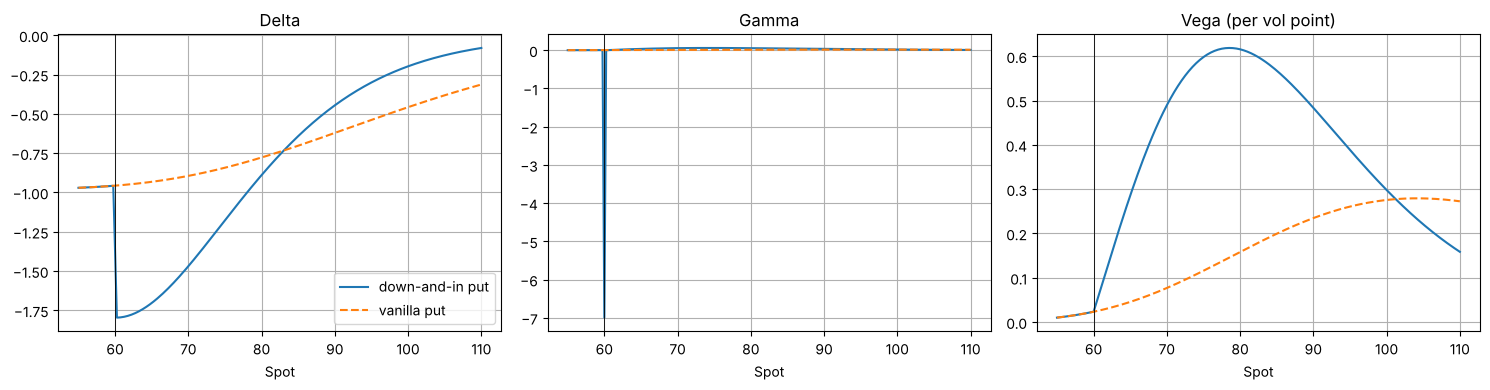

In [7]:
T_left, H, vol_low = 0.5, 60.0, 0.35
grid = np.linspace(55, 110, 221)
dip = lambda s, v: barrier_price(s, 100.0, H, T_left, rb, 0.04, v, "down-in-put")
van = lambda s, v: bs_spot(s, 100.0, T_left, rb, 0.04, v, call=False)
g_dip = [greeks_by_bump(dip, s, vol_low, h_rel=0.002) for s in grid]
g_van = [greeks_by_bump(van, s, vol_low, h_rel=0.002) for s in grid]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, key in [("Delta", "delta"), ("Gamma", "gamma"), ("Vega (per vol point)", "vega")]:
    a = ax[["delta", "gamma", "vega"].index(key)]
    a.plot(grid, [g[key] for g in g_dip], label="down-and-in put")
    a.plot(grid, [g[key] for g in g_van], "--", label="vanilla put")
    a.axvline(H, color="k", lw=0.6); a.set_title(name); a.set_xlabel("Spot")
ax[0].legend(); plt.tight_layout(); plt.show()

## 4. Caso: el producto con barrera al 60 % cuando el subyacente está al 63 %

**Situación.** Hace seis meses un cliente de banca privada compró 1 M€ de un *barrier reverse convertible* a un año
sobre *Energía Ibérica* (ficticia): cupón del 7,75 %, devolución del 100 % salvo que la acción cierre algún día por
debajo del 60 % del nivel inicial **y** termine por debajo del 100 %, en cuyo caso recibe la acción (el 100 % por
la rentabilidad final). La acción ha caído al 63 % y la volatilidad ha subido del 35 % al 42 %. El cliente pregunta
cuánto vale su producto y qué puede pasar. El banco emisor, que compró la put *down-and-in* al cliente, revisa su
cobertura.

Datos: tipo 2 %, rentabilidad por dividendo 4 %, observación diaria al cierre (BGK). Con volatilidad del 35 % el
cupón del 7,75 % deja al emisor un margen del 2 % al lanzar el producto.

In [8]:
N_note, coupon = 1_000_000.0, 0.0775
r_c, q_c, dt_obs = 0.02, 0.04, 1 / 252
def dip_daily(s, v, tau, H=60.0):
    return barrier_price_discrete(s, 100.0, H, tau, r_c, q_c, v, "down-in-put", dt_obs)
def note_value(s, v, tau):
    """Per 100 of notional: coupon and principal discounted, minus the down-and-in put the client sold."""
    return (coupon * 100 + 100) * np.exp(-r_c * tau) - dip_daily(s, v, tau)

at_issue = note_value(100.0, 0.35, 1.0)
now = note_value(63.0, 0.42, 0.5)
paths_c = gbm_paths(63.0, 0.5, r_c, q_c, 0.42, 126, 100000, seed=8)
touch = (paths_c <= 60.0).any(axis=1)
final = paths_c[:, -1]
redemption = np.where(touch & (final < 100.0), final, 100.0)
print(f"CASE note at issue (vol 35%): {at_issue:.2f}% -> today (spot 63%, vol 42%): {now:.2f}%  "
      f"= {now / 100 * N_note:,.0f} EUR for 1 M EUR")
print(f"CASE probability of closing below 60% in the next six months: {touch.mean():.0%}; "
      f"expected redemption {redemption.mean():.1f}% (plus the 7.75% coupon)")

CASE note at issue (vol 35%): 98.05% -> today (spot 63%, vol 42%): 71.23%  = 712,330 EUR for 1 M EUR
CASE probability of closing below 60% in the next six months: 86%; expected redemption 64.2% (plus the 7.75% coupon)


In [9]:
g_now = greeks_by_bump(lambda s, v: dip_daily(s, v, 0.5), 63.0, 0.42, h_rel=0.002)
g_after = greeks_by_bump(lambda s, v: bs_spot(s, 100.0, 0.5, r_c, q_c, v, call=False), 59.5, 0.42, h_rel=0.002)
g_before = greeks_by_bump(lambda s, v: dip_daily(s, v, 0.5), 60.5, 0.42, h_rel=0.002)
shares_per_note = N_note / 100.0            # the note references 10,000 shares at an initial price of 100
hedge = pd.DataFrame({
    "spot 63, barrier not hit": g_now,
    "spot 60.5, just above": g_before,
    "spot 59.5, knocked in (vanilla put)": g_after,
}).T[["price", "delta", "gamma", "vega"]]
hedge["issuer hedge (shares)"] = -hedge["delta"] * shares_per_note
print(hedge.round(4).to_string())
jump = hedge["issuer hedge (shares)"].iloc[1] - hedge["issuer hedge (shares)"].iloc[2]
print(f"CASE issuer is long {hedge['issuer hedge (shares)'].iloc[1]:,.0f} shares at 60.5 and needs {hedge['issuer hedge (shares)'].iloc[2]:,.0f} "
      f"once the barrier is hit: it sells {jump:,.0f} shares into a falling market")

                                       price   delta   gamma    vega  issuer hedge (shares)
spot 63, barrier not hit             35.4449 -1.4916  0.0208  0.1711             14915.6853
spot 60.5, just above                39.2283 -1.5307  0.0102  0.0800             15307.2568
spot 59.5, knocked in (vanilla put)  41.0175 -0.9300  0.0058  0.0433              9300.1845
CASE issuer is long 15,307 shares at 60.5 and needs 9,300 once the barrier is hit: it sells 6,007 shares into a falling market


**Lectura.**

- **Para el cliente.** El producto vale hoy bastante menos que el 100 %, aunque la barrera no se haya tocado: su
  valor ya descuenta una probabilidad alta de tocarla. Si la acción cierra por debajo del 60 %, el producto pasa
  a ser una acción más el cupón. Si no la toca, recupera el 100 %. No hay una decisión que tomar (el producto no
  se puede «salvar»), pero conviene explicarle que el precio de recompra del emisor ya refleja ese riesgo.
- **Para el emisor.** Cerca de la barrera es largo muchas acciones (la delta de la put *down-and-in* es más
  negativa que la de una put normal) y, si se toca, tiene que vender de golpe una parte en un mercado que cae.
  Es el riesgo de barrera o de salida (Schofield 7.2.4.3). Si muchos emisores tienen barreras parecidas, esas
  ventas se suman y empujan el precio hacia abajo.
- **Gap.** Si la acción abre directamente en 55, el emisor no puede ajustar la cobertura en 60: la pérdida o
  ganancia por salto no se cubre con delta. Por eso los desks aplican un *barrier shift*: valoran con la barrera
  algo desplazada hacia el spot para reservar ese coste (ejercicio avanzado).

## 5. Comprobaciones

In [10]:
assert (dig["smile effect"] > 0).all()
assert (over.overhedge > 0).all() and over.overhedge.is_monotonic_increasing
for kind, H in cases[::2]:
    other = kind.replace("-in-", "-out-")
    assert abs(barrier_price(S0, Kb, H, Tb, rb, qb, vb, kind) + barrier_price(S0, Kb, H, Tb, rb, qb, vb, other)
               - bs_spot(S0, Kb, Tb, rb, qb, vb, call=kind.endswith("call"))) < 1e-10
assert max_z < 4
assert monitor["down-in put"].is_monotonic_decreasing
assert abs(monitor.iloc[1, 2] - mc_daily) < 4 * se_daily + 0.01
assert now < at_issue and 0.5 < touch.mean() < 0.95 and abs(at_issue - 98) < 0.2
assert jump > 0
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Con la paridad in-out, ¿cuánto vale la put *down-and-out* 80 del apartado 2 si la vanilla vale lo que
   da Black-Scholes?
2. **Intermedio.** Valora la put *down-and-in* 80 con observación semanal y mensual por BGK y compárala con la diaria.
   ¿Por qué un producto con barrera solo al vencimiento (europea) es más favorable para el inversor?
3. **Avanzado.** El desk valora la put *down-and-in* del caso con la barrera desplazada a 62 (*barrier shift* de 2
   puntos) para reservar el riesgo de salto. ¿Cuánto vale esa reserva sobre el millón del cliente?

## Soluciones

In [11]:
v_put = bs_spot(S0, Kb, Tb, rb, qb, vb, call=False)
v_di = barrier_price(S0, Kb, 80, Tb, rb, qb, vb, "down-in-put")
print(f"vanilla put {v_put:.4f} - down-in {v_di:.4f} = down-out {v_put - v_di:.4f} "
      f"(formula {barrier_price(S0, Kb, 80, Tb, rb, qb, vb, 'down-out-put'):.4f})")

vanilla put 10.1975 - down-in 8.9161 = down-out 1.2815 (formula 1.2815)


In [12]:
eu_mc = np.exp(-rb * Tb) * np.where(paths[:, -1] < 80, np.maximum(Kb - paths[:, -1], 0), 0).mean()
print(monitor.round(4).to_string(index=False))
print(f"barrier observed only at maturity: {eu_mc:.4f} (Monte Carlo); with a European barrier the investor only loses")
print("if the share ends below 80, so intermediate dips do not count and the put the investor sells is cheaper.")

monitoring  effective barrier  down-in put
continuous            80.0000       8.9161
     daily            79.2694       8.7465
    weekly            78.4004       8.5292
   monthly            76.7061       8.0580
barrier observed only at maturity: 6.9737 (Monte Carlo); with a European barrier the investor only loses
if the share ends below 80, so intermediate dips do not count and the put the investor sells is cheaper.


In [13]:
shifted = dip_daily(63.0, 0.42, 0.5, H=62.0)
base = dip_daily(63.0, 0.42, 0.5, H=60.0)
print(f"down-in put with barrier 60: {base:.3f}; with 62: {shifted:.3f}; reserve {shifted - base:.3f}% "
      f"= {(shifted - base) / 100 * N_note:,.0f} EUR on 1 M EUR")

down-in put with barrier 60: 35.445; with 62: 36.798; reserve 1.353% = 13,528 EUR on 1 M EUR
